# Sistem Prediksi Risiko Stroke Berdasarkan Faktor Kesehatan dan Gaya Hidup Menggunakan Regresi Logistik

**TA-03 Praktikum Pembelajaran Mesin** | Dataset: *Stroke Prediction Dataset* (Kaggle, fedesoriano)

Alur notebook: EDA, preprocessing, penanganan class imbalance (SMOTE), pelatihan Regresi Logistik, evaluasi, lalu penyimpanan model untuk aplikasi Flask.

In [2]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve,
)
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

os.makedirs("gambar", exist_ok=True)
os.makedirs("model", exist_ok=True)

## 1. Memuat Data

In [3]:
df = pd.read_csv("data/healthcare-dataset-stroke-data.csv")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


## 2. Exploratory Data Analysis (EDA)

In [5]:
print("Missing value per kolom:")
print(df.isna().sum())
print("\nBaris duplikat:", df.duplicated().sum())
print("ID duplikat   :", df["id"].duplicated().sum())

df.describe().T

Missing value per kolom:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Baris duplikat: 0
ID duplikat   : 0


,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


In [6]:
for col in ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]:
    print(df[col].value_counts(), "\n")

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64 

ever_married
Yes    3353
No     1757
Name: count, dtype: int64 

work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64 

Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64 

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64 



### 2.1 Distribusi target (cek class imbalance)

        jumlah  persen
stroke                
0         4861   95.13
1          249    4.87


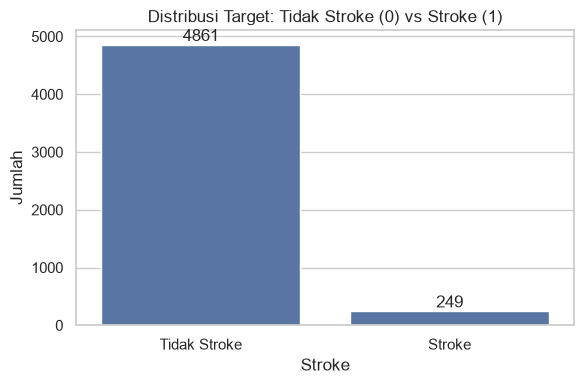

In [7]:
counts = df["stroke"].value_counts().sort_index()
pct = df["stroke"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"jumlah": counts, "persen": pct.round(2)}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x="stroke", data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Target: Tidak Stroke (0) vs Stroke (1)")
plt.xlabel("Stroke")
plt.ylabel("Jumlah")
plt.xticks([0, 1], ["Tidak Stroke", "Stroke"])
plt.tight_layout()
plt.savefig("gambar/01_distribusi_target.png", dpi=150)
plt.show()

### 2.2 Distribusi fitur numerik terhadap stroke

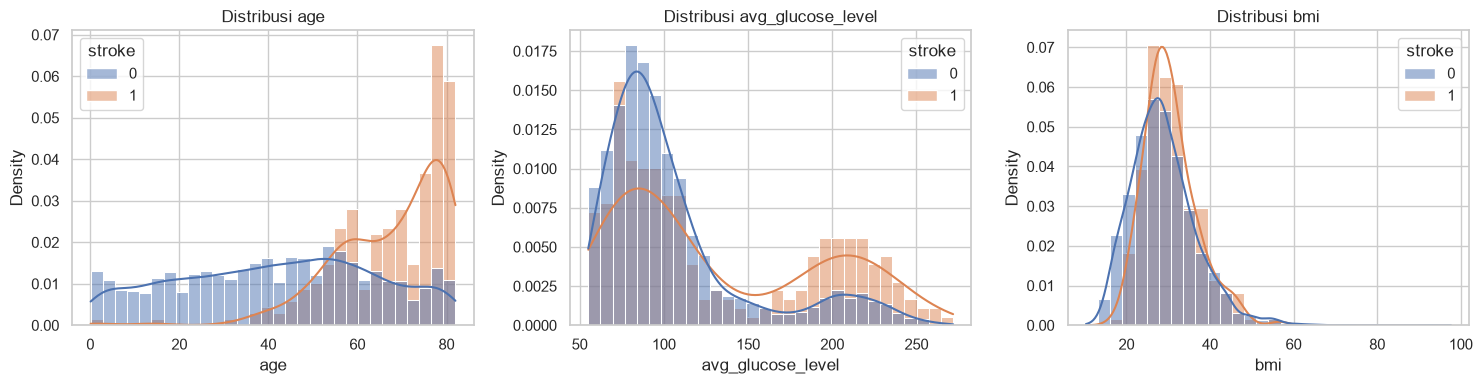

In [8]:
num_features = ["age", "avg_glucose_level", "bmi"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_features):
    sns.histplot(data=df, x=col, hue="stroke", bins=30, kde=True, stat="density",
                 common_norm=False, ax=ax)
    ax.set_title(f"Distribusi {col}")
plt.tight_layout()
plt.savefig("gambar/02_distribusi_numerik.png", dpi=150)
plt.show()

### 2.3 Tingkat stroke per kategori

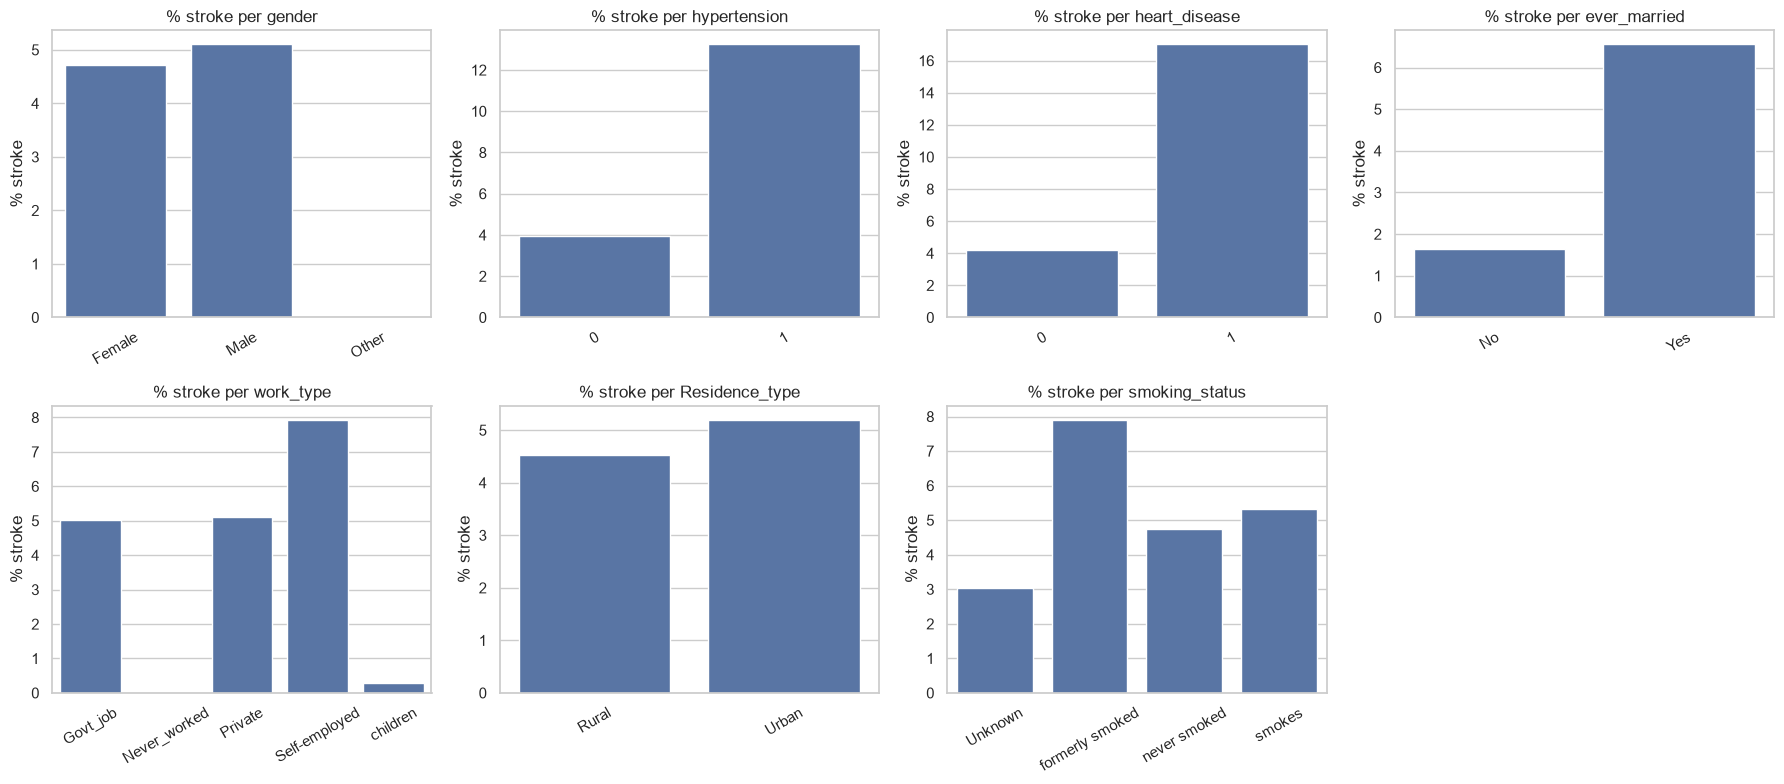

In [9]:
cat_features = ["gender", "hypertension", "heart_disease", "ever_married",
                "work_type", "Residence_type", "smoking_status"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for ax, col in zip(axes, cat_features):
    rate = df.groupby(col)["stroke"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f"% stroke per {col}")
    ax.set_ylabel("% stroke")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig("gambar/03_stroke_per_kategori.png", dpi=150)
plt.show()

### 2.4 Korelasi fitur numerik

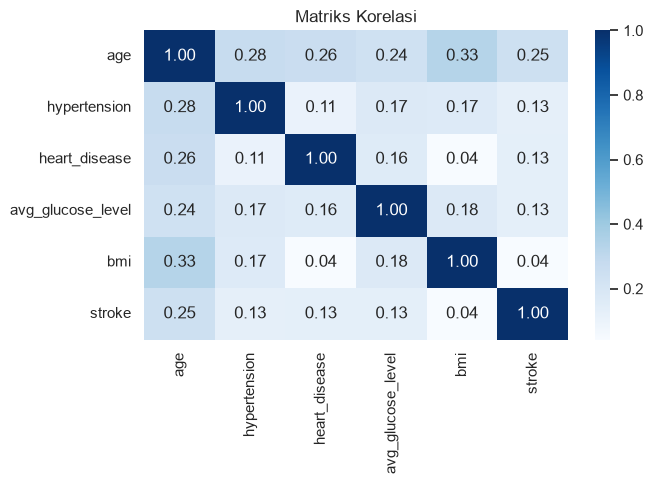

In [10]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", "stroke"]].corr(),
            annot=True, fmt=".2f", cmap="Blues")
plt.title("Matriks Korelasi")
plt.tight_layout()
plt.savefig("gambar/04_korelasi.png", dpi=150)
plt.show()

## 3. Pra-pemrosesan Data

Langkah yang dilakukan:
- Kolom `id` dibuang karena hanya pengenal, bukan fitur.
- Satu baris dengan `gender = Other` dibuang karena terlalu sedikit untuk dipelajari model.
- Nilai kosong `bmi` diisi median, dengan median dihitung **hanya dari data latih** agar tidak terjadi data leakage.
- Fitur numerik di-scaling dengan `StandardScaler`, fitur kategorikal di-*one-hot encoding*.
- Kategori `Unknown` pada `smoking_status` dipertahankan sebagai kategori sendiri (artinya informasi tidak tersedia).

In [11]:
data = df.drop(columns=["id"])
data = data[data["gender"] != "Other"].reset_index(drop=True)

X = data.drop(columns=["stroke"])
y = data["stroke"]
print(X.shape, y.shape)

(5109, 10) (5109,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Data latih :", X_train.shape, "| stroke:", y_train.sum())
print("Data uji   :", X_test.shape, "| stroke:", y_test.sum())

Data latih : (4087, 10) | stroke: 199
Data uji   : (1022, 10) | stroke: 50


In [13]:
num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
bin_cols = ["hypertension", "heart_disease"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("bin", "passthrough", bin_cols),
    ]
)

# fit HANYA pada data latih, lalu transform data latih dan data uji
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Jumlah fitur setelah preprocessing:", X_train_t.shape[1])
print(list(feature_names))

Jumlah fitur setelah preprocessing: 20
['num__age', 'num__avg_glucose_level', 'num__bmi', 'cat__gender_Female', 'cat__gender_Male', 'cat__ever_married_No', 'cat__ever_married_Yes', 'cat__work_type_Govt_job', 'cat__work_type_Never_worked', 'cat__work_type_Private', 'cat__work_type_Self-employed', 'cat__work_type_children', 'cat__Residence_type_Rural', 'cat__Residence_type_Urban', 'cat__smoking_status_Unknown', 'cat__smoking_status_formerly smoked', 'cat__smoking_status_never smoked', 'cat__smoking_status_smokes', 'bin__hypertension', 'bin__heart_disease']


## 4. Penanganan Class Imbalance dengan SMOTE

Kelas stroke jauh lebih sedikit daripada kelas tidak stroke. SMOTE membuat sampel sintetis kelas minoritas dan **hanya diterapkan pada data latih**. Data uji tetap asli agar evaluasi jujur.

Sebelum SMOTE: {0: 3888, 1: 199}
Sesudah SMOTE: {0: 3888, 1: 3888}


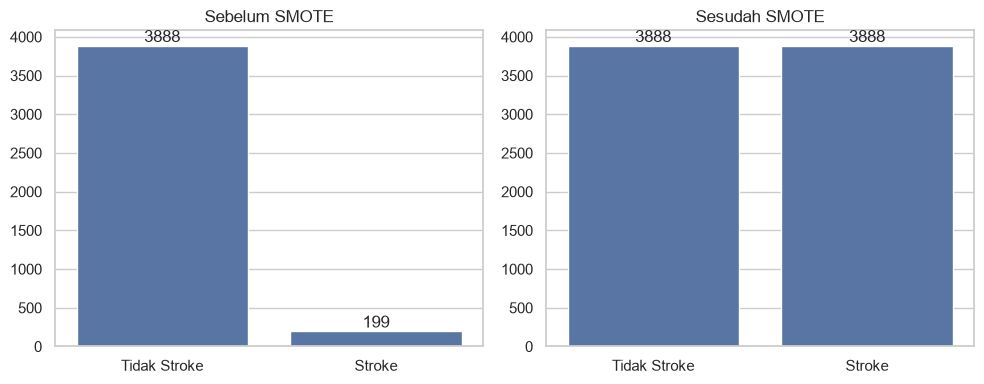

In [14]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_t, y_train)

before = y_train.value_counts().sort_index()
after = pd.Series(y_train_res).value_counts().sort_index()
print("Sebelum SMOTE:", before.to_dict())
print("Sesudah SMOTE:", after.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, s, title in zip(axes, [before, after], ["Sebelum SMOTE", "Sesudah SMOTE"]):
    sns.barplot(x=["Tidak Stroke", "Stroke"], y=s.values, ax=ax)
    ax.set_title(title)
    for i, v in enumerate(s.values):
        ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.savefig("gambar/05_smote.png", dpi=150)
plt.show()

## 5. Pelatihan Model Regresi Logistik

In [15]:
model = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_res, y_train_res)
print("Model selesai dilatih.")

Model selesai dilatih.


## 6. Evaluasi Model

Evaluasi dilakukan pada **data uji asli** (tanpa SMOTE). Pada kasus risiko stroke, **Recall kelas stroke** adalah metrik terpenting: *False Negative* (pasien berisiko diprediksi aman) lebih berbahaya daripada *False Positive* (pasien aman diprediksi berisiko, cukup dilanjutkan dengan pemeriksaan).

--- Classification Report ---
              precision    recall  f1-score   support

Tidak Stroke       0.99      0.73      0.84       972
      Stroke       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.53      1022
weighted avg       0.94      0.74      0.81      1022

TN=712  FP=260  FN=10  TP=40


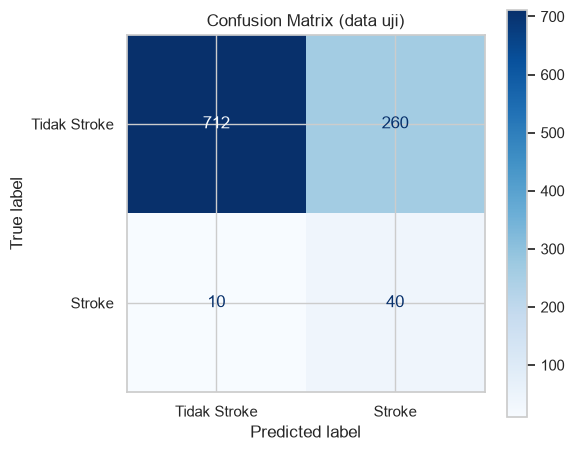

In [16]:
THRESHOLD = 0.5
y_proba = model.predict_proba(X_test_t)[:, 1]
y_pred = (y_proba >= THRESHOLD).astype(int)

print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=["Tidak Stroke", "Stroke"]))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["Tidak Stroke", "Stroke"]).plot(cmap="Blues", ax=ax)
plt.title("Confusion Matrix (data uji)")
plt.tight_layout()
plt.savefig("gambar/06_confusion_matrix.png", dpi=150)
plt.show()

In [17]:
ringkasan = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision (stroke)", "Recall (stroke)", "F1-Score (stroke)", "AUC"],
    "Nilai": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_proba),
    ],
}).round(4)
ringkasan

,Metrik,Nilai
0,Accuracy,0.7358
1,Precision (stroke),0.1333
2,Recall (stroke),0.8000
3,F1-Score (stroke),0.2286
4,AUC,0.8404


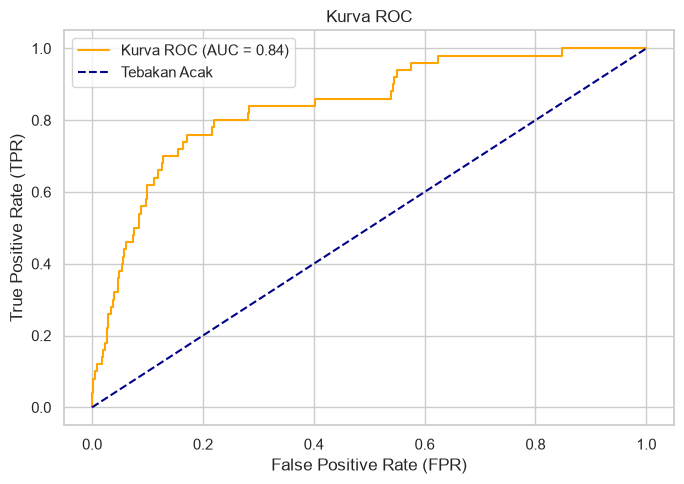

In [18]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="orange", label=f"Kurva ROC (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], color="darkblue", linestyle="--", label="Tebakan Acak")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Kurva ROC")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("gambar/07_roc.png", dpi=150)
plt.show()

### 6.1 Pengaruh threshold terhadap Precision dan Recall

Threshold 0,5 hanyalah default. Menurunkan threshold menaikkan Recall tetapi menurunkan Precision. Tabel ini membantu memilih threshold untuk laporan dan aplikasi.

In [19]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (y_proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "precision": precision_score(y_test, pred_t, zero_division=0),
        "recall": recall_score(y_test, pred_t),
        "f1": f1_score(y_test, pred_t, zero_division=0),
        "FN": int(((pred_t == 0) & (y_test == 1)).sum()),
        "FP": int(((pred_t == 1) & (y_test == 0)).sum()),
    })
pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1,FN,FP
0,0.3,0.098,0.84,0.176,8,385
1,0.4,0.116,0.84,0.204,8,320
2,0.5,0.133,0.80,0.229,10,260
3,0.6,0.166,0.76,0.272,12,191
4,0.7,0.190,0.70,0.299,15,149


## 7. Interpretasi Model (Koefisien)

Koefisien positif menaikkan peluang stroke, koefisien negatif menurunkannya. Fitur numerik sudah di-scaling, sehingga koefisiennya bisa dibandingkan satu sama lain.

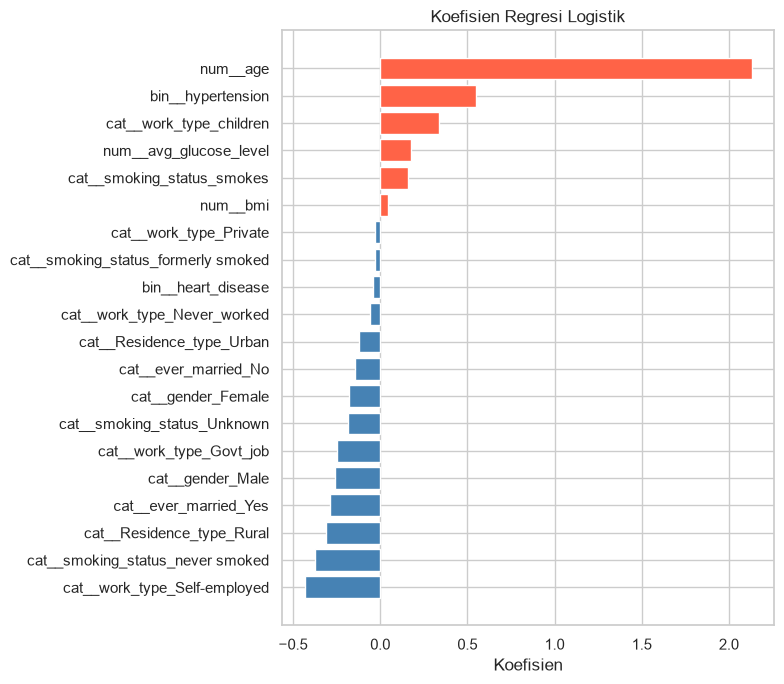

,koefisien,odds_ratio
num__age,2.131,8.420
bin__hypertension,0.547,1.729
cat__work_type_children,0.340,1.405
num__avg_glucose_level,0.175,1.192
cat__smoking_status_smokes,0.158,1.171
num__bmi,0.043,1.044
cat__work_type_Private,-0.028,0.973
cat__smoking_status_formerly smoked,-0.032,0.968
bin__heart_disease,-0.041,0.960
cat__work_type_Never_worked,-0.061,0.941


In [20]:
coef = pd.Series(model.coef_[0], index=feature_names).sort_values()
plt.figure(figsize=(8, 7))
colors = ["tomato" if v > 0 else "steelblue" for v in coef.values]
plt.barh(coef.index, coef.values, color=colors)
plt.title("Koefisien Regresi Logistik")
plt.xlabel("Koefisien")
plt.tight_layout()
plt.savefig("gambar/08_koefisien.png", dpi=150)
plt.show()

odds = pd.DataFrame({"koefisien": coef, "odds_ratio": np.exp(coef)}).round(3)
odds.sort_values("odds_ratio", ascending=False)

## 8. Menyimpan Model dengan Joblib

`preprocessor.joblib` berisi imputer, **StandardScaler**, dan encoder. File ini wajib dipakai aplikasi Flask agar input pengguna diproses dengan cara yang persis sama seperti saat training.

In [21]:
joblib.dump(preprocessor, "model/preprocessor.joblib")
joblib.dump(model, "model/model_logreg.joblib")
with open("model/config.json", "w", encoding="utf-8") as f:
    json.dump({"threshold": THRESHOLD, "features": list(X.columns)}, f, indent=2)

print(os.listdir("model"))

['config.json', 'model_logreg.joblib', 'preprocessor.joblib']


### Uji cepat: model yang disimpan bisa dimuat dan dipakai

In [22]:
pre = joblib.load("model/preprocessor.joblib")
mdl = joblib.load("model/model_logreg.joblib")

contoh = pd.DataFrame([{
    "gender": "Male", "age": 67, "hypertension": 0, "heart_disease": 1,
    "ever_married": "Yes", "work_type": "Private", "Residence_type": "Urban",
    "avg_glucose_level": 228.69, "bmi": 36.6, "smoking_status": "formerly smoked",
}])
p = mdl.predict_proba(pre.transform(contoh))[0, 1]
print(f"Probabilitas stroke: {p:.2%} -> {'Berisiko' if p >= THRESHOLD else 'Tidak Berisiko'}")

Probabilitas stroke: 81.23% -> Berisiko


## 9. Catatan untuk Laporan

Setelah **Run All**, isi bagian laporan dengan angka dari output di atas:
- Distribusi kelas dan jumlah missing value `bmi` (bagian 2)
- Hasil SMOTE sebelum dan sesudah (bagian 4)
- Confusion matrix, Precision, Recall, F1, AUC (bagian 6)
- Justifikasi pemilihan Recall dan trade-off threshold (bagian 6.1)
- Faktor yang paling berpengaruh dari koefisien (bagian 7)

Semua grafik tersimpan otomatis di folder `gambar/`.